# 2. The defects a lattice can carry

For one lattice from Notebook 1, this notebook lists every **crystalline-symmetry-breaking defect** it can carry and draws what each one looks like on the lattice.

**Where defects come from.** Cut the crystal along a line, and glue the two sides back after moving one of them by a symmetry operation g of the crystal. Far from the end of the cut nothing looks wrong, because g maps the crystal onto itself. Near the end, something must give: that is the defect. Walking once round it, a chain of bonds does not close: it is off by g, the **holonomy** of the defect.
* g a **translation** by **b**: a **dislocation** with Burgers vector **b**;
* g a **rotation** by alpha about a rotation centre: a **disclination** of Frank angle alpha (alpha > 0: a wedge removed; alpha < 0: a wedge inserted);
* g a **reflection or glide**: the sheet comes back mirrored. A point defect of this kind cannot exist on an ordinary (orientable) sheet: it needs a Moebius seam. Reflections give instead **walls** (lines).

**Which defects are the same (the homotopy classification).** Two point defects are the same type when one can be turned into the other by moving it and deforming the crystal far away. The holonomy then changes only by conjugation, g -> h g h^-1 with h a rotation or translation of G (reflections are excluded on an orientable sheet), and the rotation angle is kept as a real number (+180 and -180 are different: one removes half the plane, the other inserts it). So:
* dislocations: **b** and R **b** are the same type when R is a rotation of G;
* disclinations: same angle, and centres mapped onto each other by rotations and translations of G. A G-orbit of centres can split into two such classes (p4g: 2a(i) and 2a(ii)): they are mirror images, so their cores look identical, but they are different types.

**Walls and the other mirror- and glide-breaking defects** (four kinds):
* **(a) domain walls**: between the lattice and a copy moved by an isometry sigma that is not in G but maps G's pattern of symmetry elements onto itself (sigma in the Euclidean normaliser N(G)). The copy has the same group, but is a different domain: a mirror image (chirality domain), a rotated copy, or a shifted copy (antiphase domain). Their number is [N(G):G].
* **(b) twin walls**: the lattice on one side, its mirror image across the wall line on the other. On a mirror line of the lattice the wall is invisible.
* **(c) Moebius seams**: one per class of mirror or glide line; the sheet becomes non-orientable.
* **(d) glide-breaking walls**: on a glide line, the pure reflection instead of the glide: the two sides are off by the glide translation along the wall (a stacking fault).

**The cut-and-glue recipe for each kind.** Every defect here is made by the same Volterra procedure: cut the crystal, move one side by an isometry sigma, glue it back. What differs is the shape of the cut and the kind of sigma:

| cut | sigma | defect |
|---|---|---|
| half-line ending at a point | translation by a lattice vector **b** | dislocation (point) |
| half-line ending at a rotation centre | rotation by alpha about that centre | disclination (point) |
| half-line ending at a point | reflection or glide | impossible on an ordinary sheet: going once round the end would bring you back mirrored, and a small loop on a sheet cannot reverse orientation |
| whole line, glued back to itself across the cut | reflection or glide of the lattice | (c) Moebius seam: the sheet becomes non-orientable |
| whole line, one side replaced by its mirror image across the line | reflection that is not a symmetry | (b) twin wall (invisible on a mirror line of the lattice) |
| whole line on a glide line, one side reflected | the bare reflection instead of the glide | (d) glide-breaking wall: the sides are off by the glide translation along the wall |
| whole line, one side replaced by a moved copy | an isometry that keeps the pattern of symmetry elements but is not a symmetry (normaliser) | (a) domain wall: chirality, rotation or antiphase domains |

**Can a wall end inside the crystal?** Walk once round the would-be end: you cross the wall once, so you come back moved by the mismatch sigma between the two sides. But sigma is only defined up to the lattice's own symmetries g: side B is sigma(lattice), and that equals sigma g (lattice) for every g in G. The end must be a point defect carrying one of these sigma g, and on an ordinary sheet a point defect can only carry an orientation-preserving one (a translation or a rotation). So: **a wall can end exactly when some sigma g preserves orientation.**
* **Antiphase wall** (sigma a translation): it can end, at a partial dislocation with that Burgers vector.
* **Rotation domain wall** (sigma a rotation): it can end, at a partial disclination.
* **Glide-breaking wall**: sigma = the bare reflection, and the lattice has the glide g on that line; sigma g^-1 is a translation by the glide's slide (half a period along the line). It can end, at a partial dislocation whose Burgers vector is that slide.
* **Twin wall** (sigma a reflection across the wall): if the lattice has any mirror or glide line m, then sigma m is a rotation (two reflections make a rotation), so the twin wall is really a **tilt boundary** and can end at a partial disclination whose angle is twice the angle between the wall and that mirror line. Only on a **chiral** lattice (p1, p2, p3, p4, p6), where every sigma g reverses orientation, can a twin wall not end.
* **Chirality domain wall** (a mirror image of a chiral lattice): every sigma g reverses orientation, so it cannot end. It runs to the edge of the crystal, closes into a loop, or meets other walls.

(Argument from the holonomy: proved result; formal verification not performed. These endings are not computed by the package.)

**Status.** Classes: proved by a one-line argument from the definitions (formal verification not performed). Lists and pictures: computational evidence. For p1, pm, pg and cm the normaliser is continuous: the list (a) is a set of representatives, marked incomplete.

**Pictures.** Each defect is first built with the sites in their rigid cut-and-reglue positions. Where that would make bonds cross or overlap (near a wall line, or at some dislocation cores), the picture is redrawn: the bonds relax like springs, locally around the bad region first, and only if needed over the whole patch. The bonds themselves are never changed. A Moebius seam is the exception: a non-orientable seam cannot lie flat, so the bonds across it are drawn as dotted stubs.

In [1]:
# Setup: find the papertilling package (it sits in the folder above this notebook) and check what it needs.
import sys, pathlib, importlib.util
for _p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
    if (_p / "papertilling" / "__init__.py").exists():
        sys.path.insert(0, str(_p)); break
_kernel = "uv pip install --python '" + sys.executable + "' "
if importlib.util.find_spec("papertilling") is None:
    raise ImportError("papertilling not found. Keep this notebook inside the papertilling/notebooks folder, or install the "
                      "package into this kernel:  " + _kernel + "-e <path to the papertilling folder>")
_missing = [m for m in ("numpy", "scipy", "networkx", "matplotlib", "spglib") if importlib.util.find_spec(m) is None]
if _missing:
    raise ImportError("this kernel lacks " + ", ".join(_missing) + ". Install with:  " + _kernel + " ".join(_missing)
                      + "   (or run  %pip install " + " ".join(_missing) + "  in a cell)")
import papertilling
print("papertilling", papertilling.__version__, "| Python", sys.version.split()[0], "| numba:", importlib.util.find_spec("numba") is not None,
      "| sliders:", importlib.util.find_spec("ipywidgets") is not None)

papertilling 0.2.0 | Python 3.12.16 | numba: True | sliders: True


In [2]:
import warnings; warnings.filterwarnings("ignore", category=DeprecationWarning)
%matplotlib inline
import numpy as np, matplotlib.pyplot as plt
from papertilling.defects.catalogue import DefectCatalogue

In [3]:
# LATTICE: paste a line printed by Notebook 1 (L.code()), or take entry PICK of a group's list.
from papertilling.lattice import load_catalogue, Lattice
L = load_catalogue()["p4g"].lattices[0]        # p4g #1 (points-only rule: the Shastry-Sutherland network)
# L = Lattice.from_recipe(dict(group="p4m", sites=[(0, 0)], bonds=[((0, 0), (1, 0))], a=1))   # square lattice
# from papertilling import named; L = named("Kagomé")                                        # a named lattice
print(L)

Lattice(p4g, rank (1, 2, 4, 10): 1 site orbit(s) ['4c ..m'], 2 bond orbit(s), 4 sites and 10 bonds per primitive cell)


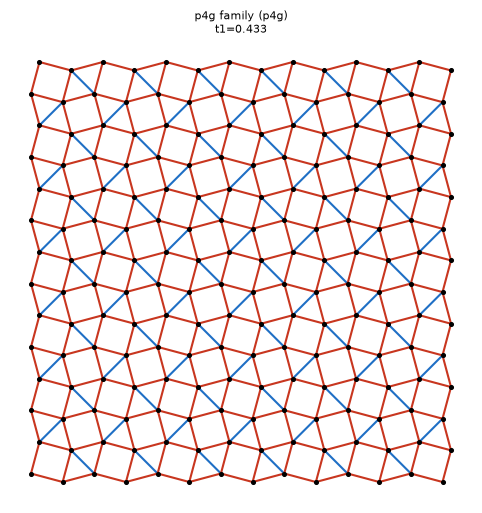

== p4g family: group p4g, |P| = 8, achiral; primitive cell a1 = (1, 0), a2 = (0, 1), 4 site(s)/cell
-- Dislocations: 2 P+-classes, 8 primitive Burgers vectors with |b| <= 2 |b_min| (|b_min| = 1)
   id   b (cell)   b (Cartesian)          |b|   angle size   -b mirror b~-b
   T1   (1, 0)     (1, 0)              1.0000    0.00    4   T1     T1 yes
   T2   (1, 1)     (1, 1)              1.4142   45.00    4   T2     T2 yes
-- Rotation-centre G+-classes: 3
   C1   2a(i)              order 4  point (0, 0)  frac (0, 0)  face centre   per cell 1  mirror -> C2
   C2   2a(ii)             order 4  point (0.5, 0.5)  frac (0.5, 0.5)  face centre   per cell 1  mirror -> C1
   C3   2b                 order 2  point (0, 0.5)  frac (0, 0.5)  bond midpoint per cell 2  mirror -> C3
-- Disclinations: 10 classes (angle in [-180, 180], +180 != -180)
   D(2a(i), -180)             face centre   H = (R(-180), (0, 0))  mirror -> D(2a(ii), -180)
   D(2a(i), -90)              face centre   H = (R(-90), (0, 0))  mir

In [4]:
fig, ax = plt.subplots(figsize=(6, 6)); L.plot(n=3, ax=ax); plt.show()
cat = DefectCatalogue(L, bmax=2.0)        # Burgers vectors up to 2 x the shortest
cat.summary();

## 1. Dislocations: the shortest Burgers vector in every direction

For each lattice direction (a primitive lattice vector), the shortest Burgers vector along it, its length, its class (the rotations of G that map it to others), whether **b** and **-b** are the same type, and its mirror partner. Each picture is one dislocation, built by cut and reglue (the cut ends at a generic point of the cell).

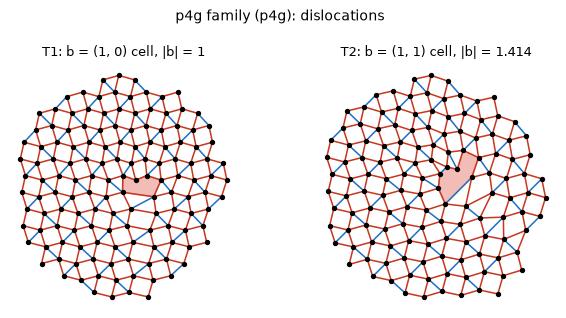

In [5]:
cat.show("dislocations"); plt.show()

## 2. Disclinations between -180 and +180 degrees

At every class of rotation centre (labelled by its ITA Wyckoff position; (i)/(ii) when a G-orbit splits), every allowed angle k x 360/n. The picture shows where the centre sits: on a site (the site loses or gains bonds), in a face (the ring round it shrinks or grows), or on a bond.

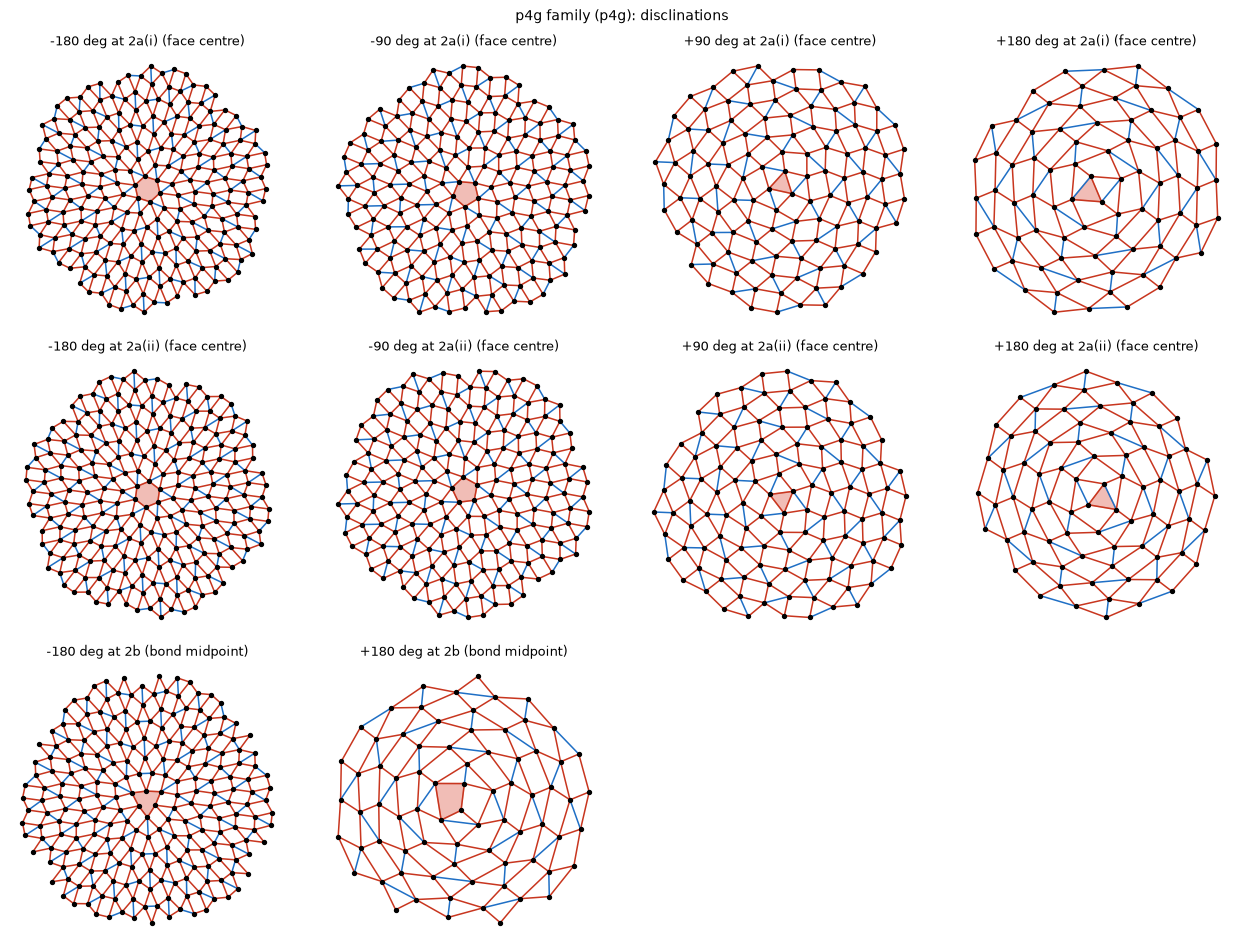

In [6]:
cat.show("disclinations"); plt.show()

## 3. Mirror and glide lines, and Moebius seams (c)

M1 mirror direction [0.707 0.707] glide 0.0 through a site: True
M2 glide direction [1. 0.] glide 0.5 through a site: False
M3 glide direction [0.707 0.707] glide 0.7071 through a site: False


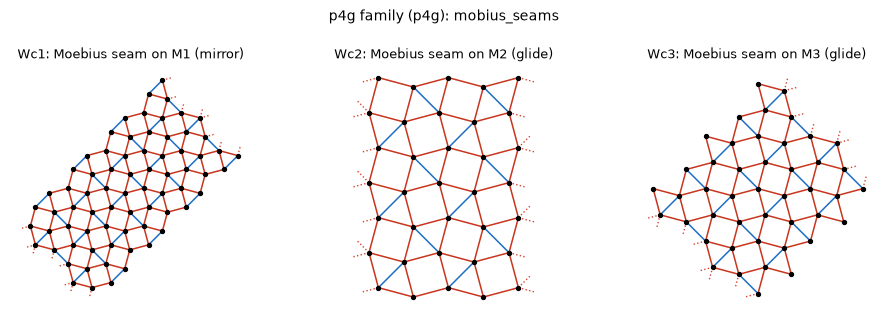

In [7]:
for m in cat.mirrors:
    print(m["id"], m["kind"], "direction", np.round(m["direction"], 3), "glide", round(m["glide"], 4), "through a site:", m["through_site"])
if cat.mobius_seams:
    cat.show("mobius_seams"); plt.show()
else:
    print("no mirror or glide: no Moebius seam (a chiral lattice)")

## 4. Domain walls (a)

The other domains with the same group: `index` = [N(G):G] counts them (with the lattice itself). Each wall here is a straight line with the lattice on one side and the moved copy on the other; bonds across the wall are cut (the bonding across a wall is not fixed by symmetry).

index equals ITA's generic value


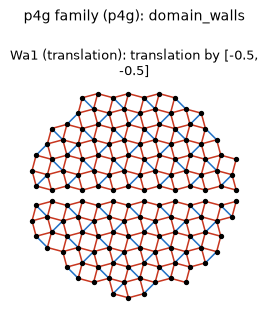

In [8]:
print(cat.normaliser["note"] if "note" in cat.normaliser else cat.normaliser)
if cat.domain_walls:
    cat.show("domain_walls"); plt.show()

## 5. Twin walls (b) and glide-breaking walls (d)

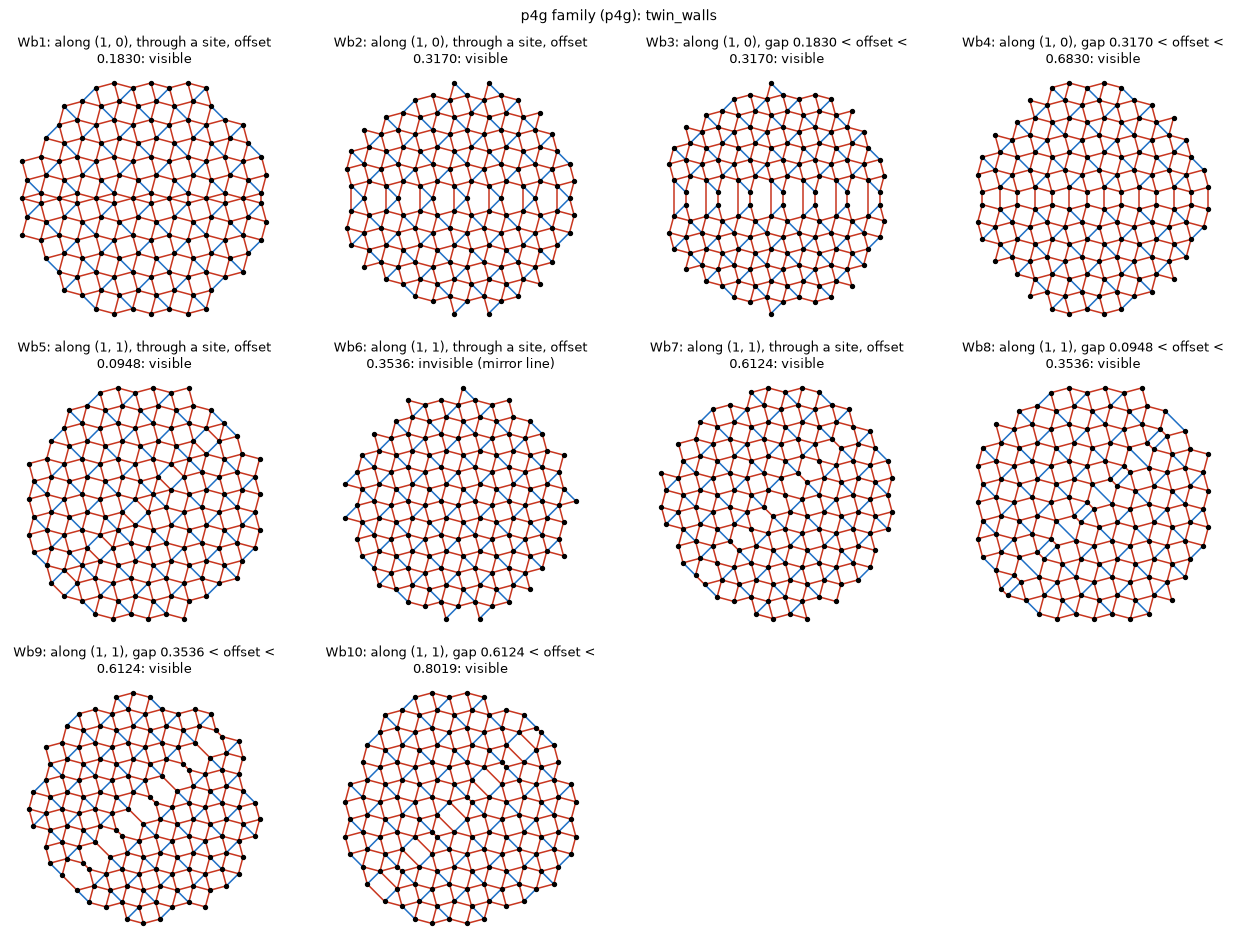

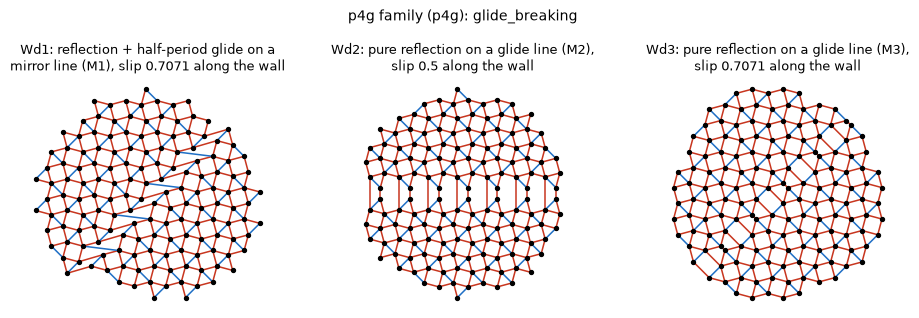

In [9]:
if cat.twin_walls:
    cat.show("twin_walls"); plt.show()
if cat.glide_breaking:
    cat.show("glide_breaking"); plt.show()

## 6. One defect up close

Every entry has `build(R=...)` (a larger patch with `R`) and `plot(ax)`. Its `spec` is what Notebook 3 takes.

D(2a(i), -180) {'kind': 'disclination', 'angle': -180.0, 'at': (0.0, 0.0)}


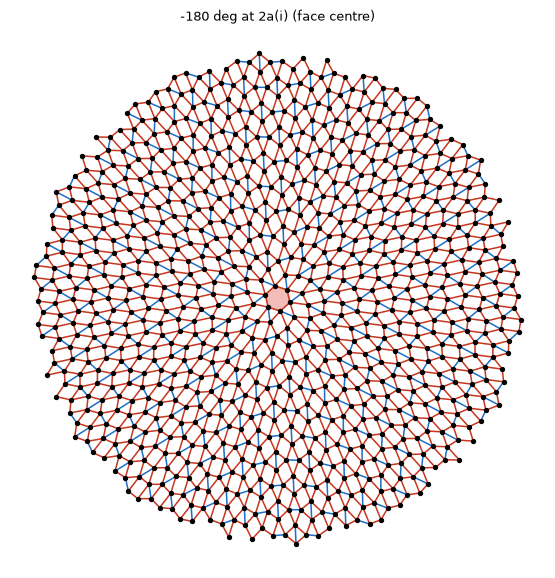

In [10]:
e = cat.disclinations[0]
print(e["id"], e["spec"])
fig, ax = plt.subplots(figsize=(7, 7)); e.plot(ax=ax, R=7); plt.show()